> **Portfolio summary:** Credit-card default prediction: Random Forest vs XGBoost vs the TabPFN foundation model.
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

## Introduction

In the realm of financial risk management, predicting credit card default is a critical task. This analysis explores the performance of various machine learning models—namely Random Forest, XGBoost, and TabPFN—in forecasting whether a credit card client will default on their next payment. The goal is to understand which models excel in accuracy, F1-score, and AUC-ROC, offering insights into their strengths and weaknesses for this specific classification challenge.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset from the URL
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00350/default%20of%20credit%20card%20clients.xls'
df = pd.read_excel(url, header=1)

# Remove 'ID' column as it is not predictive
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

In [ ]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:


# Define target and features
target_col = 'default payment next month'
y = df[target_col]
X = df.drop(columns=[target_col])

# Split the data into training and testing sets (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Verify the split by printing shapes
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

Training features shape: (22500, 23)
Testing features shape: (7500, 23)
Training target shape: (22500,)
Testing target shape: (7500,)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Initialize models
rf_model = RandomForestClassifier(random_state=42)
# Removed use_label_encoder=False to avoid UserWarning in newer XGBoost versions
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

# 2. Fit models
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# 3. Generate predictions and probabilities
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# 4. Calculate metrics
rf_metrics = {
    'Accuracy': accuracy_score(y_test, rf_preds),
    'F1-score': f1_score(y_test, rf_preds),
    'AUC-ROC': roc_auc_score(y_test, rf_probs)
}

xgb_metrics = {
    'Accuracy': accuracy_score(y_test, xgb_preds),
    'F1-score': f1_score(y_test, xgb_preds),
    'AUC-ROC': roc_auc_score(y_test, xgb_probs)
}

print(f"Random Forest Metrics: {rf_metrics}")
print(f"XGBoost Metrics: {xgb_metrics}")

Random Forest Metrics: {'Accuracy': 0.816, 'F1-score': 0.45839874411302983, 'AUC-ROC': np.float64(0.7533857136473299)}
XGBoost Metrics: {'Accuracy': 0.8126666666666666, 'F1-score': 0.45605884630274873, 'AUC-ROC': np.float64(0.7595286462451327)}

In [ ]:
!pip install "tabpfn<2.0.0"

In [ ]:
import warnings
import torch.nn.modules.transformer
import typing
import torch
import sys
import os
from tabpfn import TabPFNClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Suppress specific warnings to clean up output
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# Monkey-patch torch to fix tabpfn 0.1.11 compatibility with modern torch
if not hasattr(torch.nn.modules.transformer, 'Optional'):
    torch.nn.modules.transformer.Optional = typing.Optional

# 2. Select a representative subset of 1000 samples for training
X_train_subset = X_train.iloc[:1000]
y_train_subset = y_train.iloc[:1000]

# 3. Initialize the TabPFNClassifier
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tabpfn = TabPFNClassifier(device=device, N_ensemble_configurations=32)

# 4. Fit the model and generate predictions/probabilities with captured stderr
# This block ensures that even low-level C/Torch warnings are suppressed from the UI
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    stderr = sys.stderr
    sys.stderr = open(os.devnull, 'w')
    try:
        tabpfn.fit(X_train_subset, y_train_subset)
        tabpfn_preds = tabpfn.predict(X_test)
        tabpfn_probs = tabpfn.predict_proba(X_test)[:, 1]
    finally:
        sys.stderr.close()
        sys.stderr = stderr

# 5. Calculate metrics
tabpfn_metrics = {
    'Accuracy': accuracy_score(y_test, tabpfn_preds),
    'F1-score': f1_score(y_test, tabpfn_preds),
    'AUC-ROC': roc_auc_score(y_test, tabpfn_probs)
}

print(f"TabPFN Metrics: {tabpfn_metrics}")

TabPFN Metrics: {'Accuracy': 0.8116, 'F1-score': 0.3912106850495476, 'AUC-ROC': np.float64(0.7527552828665679)}

## Visualization


Consolidated Performance Metrics:

,Model,Accuracy,F1-score,AUC-ROC
0,Random Forest,0.816000,0.458399,0.753386
1,XGBoost,0.812667,0.456059,0.759529
2,TabPFN,0.811600,0.391211,0.752755


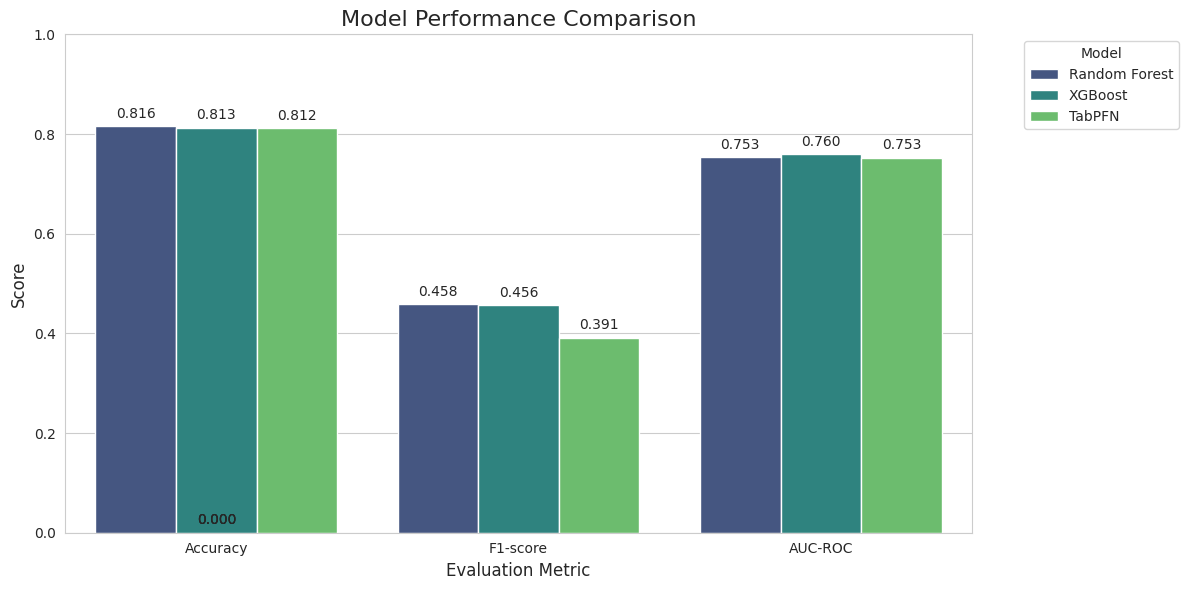

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create a consolidated DataFrame from the metrics dictionaries
results_df = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'TabPFN'],
    'Accuracy': [rf_metrics['Accuracy'], xgb_metrics['Accuracy'], tabpfn_metrics['Accuracy']],
    'F1-score': [rf_metrics['F1-score'], xgb_metrics['F1-score'], tabpfn_metrics['F1-score']],
    'AUC-ROC': [float(rf_metrics['AUC-ROC']), float(xgb_metrics['AUC-ROC']), float(tabpfn_metrics['AUC-ROC'])]
})

print("Consolidated Performance Metrics:")
display(results_df)

# 2. Reshape the DataFrame for plotting (melt)
df_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Value')

# 3. Create the grouped bar chart
plt.figure(figsize=(12, 6))
sns.set_style("whitegrid")
ax = sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='viridis')

# 4. Customize the plot
plt.title('Model Performance Comparison', fontsize=16)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.ylim(0, 1.0)
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')

# 5. Annotate each bar with its numerical value
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.3f'),
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha = 'center', va = 'center',
                   xytext = (0, 9),
                   textcoords = 'offset points')

plt.tight_layout()
plt.show()